# Linux Error Diagnoser — Lab 9 : notebook final
**Yassir ALAKHOUCH · Yasser BENDI**

Pipeline complet : **classer → retrouver → rédiger (Gemini) → signaler les commandes risquées**, puis évaluation contre les baselines et **analyse élargie** (remarque du Lab 8).

| Partie | Contenu |
|---|---|
| 1–3 | Installation, données, contrôle de couverture |
| 4 | Retriever : BM25, embeddings, hybride RRF |
| 5 | Classifieur entraîné (remplace les prototypes du Lab 8) + détection « other » |
| 6 | Pipeline : filtre dur vs filtre doux vs oracle |
| 7 | Drafter Gemini avec citations ou escalade |
| 8 | Évaluation de bout en bout vs **Gemini seul** |
| 9 | **Analyse élargie** : métriques, intervalles de confiance, tests appariés, catégories, sensibilité, robustesse, flagger, latence |
| 10 | Bilan de la claim, export, démo |

**Avant de lancer :**
1. 🔑 *Secrets* (barre de gauche) → ajouter `GEMINI_API_KEY` (clé de https://aistudio.google.com/apikey), activer *Accès au notebook*.
2. CPU suffit. *Exécution → Tout exécuter*. Durée : ~5 min de calcul + ~7 min d'appels Gemini (48 appels). Si un modèle n'a plus de quota pour la journée, le notebook passe tout seul au modèle suivant.
3. Sans clé, le notebook tourne quand même : les parties 7–8 sont simplement sautées.

## 1 · Installation et configuration

In [1]:
!pip install -q rank_bm25 sentence-transformers google-genai

In [2]:
import os, sys, json, re, time, hashlib, random, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/linux-err-diag"):
        !git clone -q https://github.com/Zbalbolaa/linux-err-diag.git
    %cd /content/linux-err-diag
sys.path.insert(0, "src")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---- Réglages ----
SEED = 0
EMB_MODEL = "all-MiniLM-L6-v2"          # modèle du Lab 8
EMB_MODEL_2 = "BAAI/bge-small-en-v1.5"  # 2e modèle, pour l'analyse de sensibilité
COMPARE = False       # True = sensibilité complète (2e modèle, titres, 1000 car.) : +5 min CPU
TRUNC = 300           # caractères encodés par section (Lab 8)
N_PASSAGES = 5        # sections données au drafter (3 avant : trop peu)
PASSAGE_CHARS = 2500  # caractères par section donnée au drafter (1200 avant)
RUN_LLM = True        # parties 7-8 (Gemini)
MODEL_OVERRIDE = None # ex. "gemini-2.5-flash" pour forcer un modèle
LLM_SLEEP = 8         # secondes entre deux appels (limite gratuite)
JUDGE_ON = False      # True = note de la correction par un juge Gemini (2x plus d'appels)
OUT = "results"; os.makedirs(OUT, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
GREEN, DARK, GREY, ORANGE, BLUE = "#2EA043", "#0D1117", "#8B949E", "#D29922", "#58A6FF"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()
SUMMARY = {}

/content/linux-err-diag


## 2 · Données

In [3]:
S  = pd.DataFrame([json.loads(l) for l in open("data/corpus.jsonl", encoding="utf-8")])
EV = pd.DataFrame([json.loads(l) for l in open("data/eval_24.jsonl", encoding="utf-8")])

def norm(p):
    p = str(p).lower().strip()
    p = re.sub(r"https?://wiki\.archlinux\.org/title/", "", p)
    return p.split("#")[0].replace("_", " ").strip()

S["page_n"] = S["page"].map(norm)
EV["ref_n"] = EV["ref_page"].map(lambda p: norm(p) if isinstance(p, str) and p else None)
PAGES, DOM = S["page_n"].values, S["domain"].values
DOMAINS = sorted(S["domain"].unique())

COV   = EV[EV.type == "covered"].reset_index(drop=True)        # 18 : la claim
OOC   = EV[EV.type == "out_of_corpus"].reset_index(drop=True)  # 3  : à escalader
RISKY = EV[EV.type == "risky"].reset_index(drop=True)          # 3  : commande dangereuse
RET   = EV[EV.ref_n.notna()].reset_index(drop=True)            # 21 : tous les cas avec page de référence

print(f"Corpus : {len(S)} sections, {S.page_n.nunique()} pages, domaines = {DOMAINS}")
print(S.domain.value_counts().to_dict())
print(f"Évaluation : {len(EV)} cas -> {len(COV)} couverts, {len(OOC)} hors corpus, {len(RISKY)} risqués")
missing = set(RET.ref_n) - set(S.page_n)
print("Pages de référence absentes du corpus :", missing or "aucune ✓")
dom_of_ref = {p: S[S.page_n == p].domain.mode()[0] for p in set(RET.ref_n) if p in set(S.page_n)}
mism = [(r.id, r.category, dom_of_ref.get(r.ref_n)) for r in RET.itertuples() if dom_of_ref.get(r.ref_n) != r.category]
print("Cas dont la page de référence est rangée dans un autre domaine du corpus :", mism)
print("Source des erreurs :", EV.source.value_counts().to_dict())
SUMMARY["data"] = dict(sections=len(S), pages=int(S.page_n.nunique()), covered=len(COV), ooc=len(OOC),
                       risky=len(RISKY), domain_mismatch=[m[0] for m in mism])

Corpus : 2995 sections, 143 pages, domaines = ['boot_systemd', 'disks', 'display', 'network', 'pacman', 'permissions']
{'display': 611, 'network': 577, 'boot_systemd': 576, 'disks': 452, 'permissions': 409, 'pacman': 370}
Évaluation : 24 cas -> 18 couverts, 3 hors corpus, 3 risqués
Pages de référence absentes du corpus : aucune ✓
Cas dont la page de référence est rangée dans un autre domaine du corpus : []
Source des erreurs : {'TODO: real|synthetic': 24}


## 3 · Briques communes (scores, rangs)
Un système de recherche = une fonction `q -> score de chaque section`. Le rang d'une page = sa position parmi les **pages distinctes** (même règle qu'au Lab 8).

In [4]:
def page_order(scores, n=50):
    seen = []
    for i in np.argsort(-scores):
        if PAGES[i] not in seen:
            seen.append(PAGES[i])
            if len(seen) == n: break
    return seen

def top_sections(scores, n=3):
    out, seen = [], set()
    for i in np.argsort(-scores):
        if PAGES[i] in seen: continue
        seen.add(PAGES[i]); out.append(i)
        if len(out) == n: break
    return out

def rank_of(scores, ref, n=50):
    po = page_order(scores, n)
    return po.index(ref) + 1 if ref in po else n + 1

def ranks(score_fn, cases):
    return np.array([rank_of(score_fn(e), r) for e, r in zip(cases.error, cases.ref_n)])

def metrics(rk):
    rk = np.asarray(rk)
    return {"Top-1": int((rk <= 1).sum()), "Top-3": int((rk <= 3).sum()), "Top-5": int((rk <= 5).sum()),
            "MRR": round(float((1 / rk).mean()), 3), "n": len(rk)}

def mtable(d, label=None):
    t = pd.DataFrame(d).T
    for c in ["Top-1", "Top-3", "Top-5", "n"]: t[c] = t[c].astype(int)
    return t.rename_axis(label) if label else t

def boot_ci(x, B=5000):
    x = np.asarray(x, float)
    m = x[rng.integers(0, len(x), (B, len(x)))].mean(1)
    return np.percentile(m, [2.5, 97.5])

## 4 · Retriever : BM25, embeddings, hybride

In [5]:
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

TOK = re.compile(r"[a-z0-9_.\-/]+")
tok = lambda s: TOK.findall(str(s).lower())
T_INDEX = {}

def make_bm25(texts):
    idx = BM25Okapi([tok(t) for t in texts]); cache = {}
    def f(q):
        if q not in cache: cache[q] = idx.get_scores(tok(q))
        return cache[q]
    return f

t0 = time.time(); s_bm25 = make_bm25(S.text); T_INDEX["BM25"] = time.time() - t0

ENCODERS = {}
def encoder(name):
    if name not in ENCODERS: ENCODERS[name] = SentenceTransformer(name)
    return ENCODERS[name]

def make_emb(name, texts, qprefix=""):
    m = encoder(name); t0 = time.time()
    Emat = m.encode(list(texts), normalize_embeddings=True, batch_size=64, show_progress_bar=True)
    dt = time.time() - t0; cache = {}
    def qv(q):
        if q not in cache: cache[q] = m.encode(qprefix + q, normalize_embeddings=True)
        return cache[q]
    f = lambda q: Emat @ qv(q)
    f.qv, f.E, f.t = qv, Emat, dt
    return f

s_emb = make_emb(EMB_MODEL, [t[:TRUNC] for t in S.text]); T_INDEX["Embeddings"] = s_emb.t
E, qvec = s_emb.E, s_emb.qv

def rrf(*score_arrays, k=60):
    out = np.zeros(len(S))
    for s in score_arrays:
        out[np.argsort(-s)] += 1 / (k + np.arange(1, len(s) + 1))
    return out

def make_hybrid(fb, fe, k=60): return lambda q: rrf(fb(q), fe(q), k=k)
s_hyb = make_hybrid(s_bm25, s_emb)

SYS = {"BM25": s_bm25, "Embeddings": s_emb, "Hybride RRF": s_hyb}
R18 = {k: ranks(f, COV) for k, f in SYS.items()}
R21 = {k: ranks(f, RET) for k, f in SYS.items()}
print("Indexation (s) :", {k: round(v, 1) for k, v in T_INDEX.items()})
display(mtable({k: metrics(v) for k, v in R18.items()}, "18 cas couverts"))
print("Contrôle Lab 8 attendu : BM25 12, Embeddings 13, Hybride 14 (top-3 /18)")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Indexation (s) : {'BM25': 0.5, 'Embeddings': 159.2}


,Top-1,Top-3,Top-5,MRR,n
18 cas couverts,,,,,
BM25,6,12,12,0.508,18
Embeddings,8,13,14,0.611,18
Hybride RRF,8,14,15,0.613,18


Contrôle Lab 8 attendu : BM25 12, Embeddings 13, Hybride 14 (top-3 /18)


## 5 · Classifieur entraîné (remplace les prototypes du Lab 8)
Au Lab 8 on n'avait pas de données d'entraînement. Or **chaque section du corpus porte déjà son domaine** : 2 995 exemples étiquetés gratuitement (supervision faible : du texte de wiki, pas des messages d'erreur).

| Méthode | Entraînement |
|---|---|
| A. Prototypes (Lab 8) | aucun |
| B. TF-IDF + régression logistique | 2 995 sections |
| C. Embeddings + régression logistique | 2 995 sections |
| D. C + erreurs réelles, **leave-one-out** | 2 995 sections + 20 erreurs (la 21e est testée, jamais vue) |

On évalue sur les 21 erreurs des 6 domaines, puis la capacité à reconnaître les 3 erreurs **hors corpus** grâce à la confiance du modèle.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

IN  = EV[EV.category.isin(DOMAINS)].reset_index(drop=True)   # 21
OTH = EV[~EV.category.isin(DOMAINS)].reset_index(drop=True)  # 3
Q_IN  = np.vstack([qvec(e) for e in IN.error]); Q_OTH = np.vstack([qvec(e) for e in OTH.error])
y_in = IN.category.values
CLF = {}

# A. prototypes (Lab 8)
PROTO_TXT = {
 "pacman":       "pacman package signature keyring database lock conflict mirror",
 "boot_systemd": "systemd boot service failed unit grub initramfs kernel panic",
 "network":      "network connection dns wifi unreachable networkmanager resolve",
 "permissions":  "permission denied sudo chmod chown access not permitted",
 "disks":        "disk mount filesystem partition fstab no space left device",
 "display":      "display xorg wayland gpu driver screen monitor",
}
P = np.vstack([qvec(PROTO_TXT[d]) for d in DOMAINS])
def proto_pc(Q):
    s = Q @ P.T
    return np.array(DOMAINS)[s.argmax(1)], s.max(1)
CLF["A. Prototypes (Lab 8)"] = (*proto_pc(Q_IN), proto_pc(Q_OTH)[1], proto_pc(Q_OTH)[0])

# B. TF-IDF + LR sur le corpus
tfidf_lr = make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2,
                                         token_pattern=r"[A-Za-z0-9_.\-/]{2,}"),
                         LogisticRegression(max_iter=3000, C=5, class_weight="balanced"))
tfidf_lr.fit(S.text, S.domain)
pb_in, pb_oth = tfidf_lr.predict_proba(IN.error), tfidf_lr.predict_proba(OTH.error)
CLF["B. TF-IDF + LR"] = (tfidf_lr.classes_[pb_in.argmax(1)], pb_in.max(1), pb_oth.max(1), tfidf_lr.classes_[pb_oth.argmax(1)])

# C. Embeddings + LR sur le corpus
LR = LogisticRegression(max_iter=3000, C=2.0, class_weight="balanced")
emb_lr = clone(LR).fit(E, S.domain)
pc_in, pc_oth = emb_lr.predict_proba(Q_IN), emb_lr.predict_proba(Q_OTH)
CLF["C. Embeddings + LR"] = (emb_lr.classes_[pc_in.argmax(1)], pc_in.max(1), pc_oth.max(1), emb_lr.classes_[pc_oth.argmax(1)])

# D. C + erreurs réelles, leave-one-out (aucune fuite : l'erreur testée n'est jamais dans l'entraînement)
W_ERR = 30.0
def fit_d(mask):
    X = np.vstack([E, Q_IN[mask]]); y = np.r_[S.domain.values, y_in[mask]]
    w = np.r_[np.ones(len(E)), np.full(mask.sum(), W_ERR)]
    return clone(LR).fit(X, y, sample_weight=w)
pd_pred, pd_conf = [], []
for i in range(len(IN)):
    mask = np.ones(len(IN), bool); mask[i] = False
    c = fit_d(mask); p = c.predict_proba(Q_IN[i:i + 1])[0]
    pd_pred.append(c.classes_[p.argmax()]); pd_conf.append(p.max())
final_clf = fit_d(np.ones(len(IN), bool))       # modèle final (démo + cas hors corpus)
pd_oth = final_clf.predict_proba(Q_OTH)
CLF["D. Emb + LR + erreurs (LOO)"] = (np.array(pd_pred), np.array(pd_conf), pd_oth.max(1),
                                     final_clf.classes_[pd_oth.argmax(1)])

# E. B + les erreurs du jeu de test, leave-one-out (comme D, mais avec TF-IDF)
def fit_e(mask):
    c = make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2,
                                      token_pattern=r"[A-Za-z0-9_.\-/]{2,}"),
                      LogisticRegression(max_iter=3000, C=5))
    X = list(S.text) + list(IN.error[mask]); y = list(S.domain) + list(y_in[mask])
    w = np.r_[np.ones(len(S)), np.full(mask.sum(), W_ERR)]
    return c.fit(X, y, logisticregression__sample_weight=w)
pe_pred, pe_conf = [], []
for i in range(len(IN)):
    mask = np.ones(len(IN), bool); mask[i] = False
    c = fit_e(mask); p = c.predict_proba([IN.error[i]])[0]
    pe_pred.append(c.classes_[p.argmax()]); pe_conf.append(p.max())
final_tfidf = fit_e(np.ones(len(IN), bool)); pe_oth = final_tfidf.predict_proba(list(OTH.error))
CLF["E. TF-IDF + erreurs (LOO)"] = (np.array(pe_pred), np.array(pe_conf), pe_oth.max(1),
                                   final_tfidf.classes_[pe_oth.argmax(1)])

# F. Essai : une vraie classe "other" apprise sur 40 erreurs d'outils HORS périmètre, écrites à la main
# (aucun des outils du test hors corpus : kubectl, git, terraform). Mesuré, mais pas retenu s'il n'aide pas.
OTHER_TRAIN = [
 "docker: Cannot connect to the Docker daemon at unix:///var/run/docker.sock. Is the docker daemon running?",
 "Error response from daemon: Conflict. The container name \"/web\" is already in use by container 3f2a",
 "docker: Error response from daemon: pull access denied for myimage, repository does not exist",
 "npm ERR! code ERESOLVE npm ERR! ERESOLVE unable to resolve dependency tree",
 "npm ERR! Missing script: \"start\"",
 "Error: Cannot find module 'express' Require stack: - /app/index.js",
 "ModuleNotFoundError: No module named 'numpy'",
 "Traceback (most recent call last): File \"app.py\", line 3, in <module> KeyError: 'DATABASE_URL'",
 "error: externally-managed-environment This environment is externally managed",
 "SyntaxError: invalid syntax (main.py, line 12)",
 "Exception in thread \"main\" java.lang.NullPointerException at com.example.App.main(App.java:14)",
 "error: could not find `Cargo.toml` in `/home/user/project` or any parent directory",
 "error[E0382]: borrow of moved value: `v`",
 "[ERROR] Failed to execute goal org.apache.maven.plugins:maven-compiler-plugin:3.8.1:compile",
 "FAILURE: Build failed with an exception. Could not resolve all files for configuration ':app:debugCompileClasspath'.",
 "ERROR 1045 (28000): Access denied for user 'root'@'localhost' (using password: YES)",
 "psql: error: connection to server on socket \"/run/postgresql/.s.PGSQL.5432\" failed: FATAL: role \"user\" does not exist",
 "Could not connect to Redis at 127.0.0.1:6379: Connection refused",
 "MongoServerError: Authentication failed.",
 "fatal: [web01]: UNREACHABLE! => {\"changed\": false, \"msg\": \"Failed to connect to the host via ssh\"}",
 "An error occurred (AccessDenied) when calling the ListBuckets operation: Access Denied",
 "ERROR: (gcloud.compute.instances.create) Could not fetch resource: The resource 'projects/x' was not found",
 "Error: listen EADDRINUSE: address already in use :::3000",
 "TypeError: Cannot read properties of undefined (reading 'map')",
 "CMake Error at CMakeLists.txt:5 (find_package): Could not find a package configuration file provided by \"Qt5\"",
 "make: *** No rule to make target 'install'. Stop.",
 "gcc: error: unrecognized command-line option '-std=c++23'",
 "ld: cannot find -lssl: No such file or directory",
 "LaTeX Error: File `tikz.sty' not found.",
 "Error: Could not find or load main class Main",
 "Segmentation fault (core dumped) ./a.out",
 "ImportError: libGL.so.1: cannot open shared object file: No such file or directory (opencv)",
 "CUDA error: out of memory. Tried to allocate 2.00 GiB",
 "Unhandled Exception: System.IO.FileNotFoundException: Could not load file or assembly 'Newtonsoft.Json'",
 "PHP Fatal error:  Uncaught Error: Call to undefined function mysqli_connect()",
 "rake aborted! Gem::LoadError: You have already activated rack 2.2.3",
 "Error: Process completed with exit code 1. (GitHub Actions)",
 "SSL: CERTIFICATE_VERIFY_FAILED certificate verify failed: unable to get local issuer certificate (python requests)",
 "vite v5: [plugin:vite:import-analysis] Failed to resolve import \"./App.vue\"",
 "Error: ENOENT: no such file or directory, open '/app/config.json'",
]
clf_other = make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2,
                                          token_pattern=r"[A-Za-z0-9_.\-/]{2,}"),
                          LogisticRegression(max_iter=3000, C=5))
clf_other.fit(list(S.text) + OTHER_TRAIN, list(S.domain) + ["other"] * len(OTHER_TRAIN))
pf_in, pf_oth = clf_other.predict_proba(IN.error), clf_other.predict_proba(OTH.error)
CLF["F. B + classe « other » (essai)"] = (clf_other.classes_[pf_in.argmax(1)], pf_in.max(1), pf_oth.max(1),
                                         clf_other.classes_[pf_oth.argmax(1)])

rows = []
for k, (pred, cin, coth, poth) in CLF.items():
    acc = (pred == y_in)
    lo, hi = boot_ci(acc)
    rows.append({"Méthode": k, "Accuracy /21": f"{acc.sum()}/21", "IC 95 %": f"[{lo:.0%}–{hi:.0%}]",
                 "Hors corpus → other /3": int((poth == "other").sum()),
                 "Couverts → other à tort /21": int((pred == "other").sum()),
                 "Confiance moy. (6 domaines)": round(float(cin.mean()), 2),
                 "Confiance moy. (hors corpus)": round(float(coth.mean()), 2)})
CLF_TABLE = pd.DataFrame(rows); display(CLF_TABLE)
SUMMARY["classifier"] = {r["Méthode"]: r["Accuracy /21"] for r in rows}
# Classifieur retenu : meilleure accuracy parmi B–E (A = référence Lab 8) ; à égalité, celui qui reconnaît
# le plus d'erreurs hors corpus. Prédictions sans fuite.
BEST_CLF = max([k for k in CLF if k[0] in "BCDEF"], key=lambda k: ((CLF[k][0] == y_in).sum() + (CLF[k][3] == "other").sum(),
                                             (CLF[k][0] == y_in).sum(), -(CLF[k][0] == "other").sum()))
PRED_LOO = dict(zip(IN.id, CLF[BEST_CLF][0])); CONF_LOO = dict(zip(IN.id, CLF[BEST_CLF][1]))
print("Classifieur retenu pour le pipeline :", BEST_CLF)
SUMMARY["classifier_choice"] = BEST_CLF

,Méthode,Accuracy /21,IC 95 %,Hors corpus → other /3,Couverts → other à tort /21,Confiance moy. (6 domaines),Confiance moy. (hors corpus)
0,A. Prototypes (Lab 8),17/21,[62%–95%],0,0,0.33,0.21
1,B. TF-IDF + LR,19/21,[76%–100%],0,0,0.48,0.65
2,C. Embeddings + LR,17/21,[62%–95%],0,0,0.70,0.60
3,D. Emb + LR + erreurs (LOO),17/21,[62%–95%],0,0,0.73,0.60
4,E. TF-IDF + erreurs (LOO),20/21,[86%–100%],0,0,0.59,0.75
5,F. B + classe « other » (essai),15/21,[52%–90%],0,4,0.46,0.58


Classifieur retenu pour le pipeline : E. TF-IDF + erreurs (LOO)


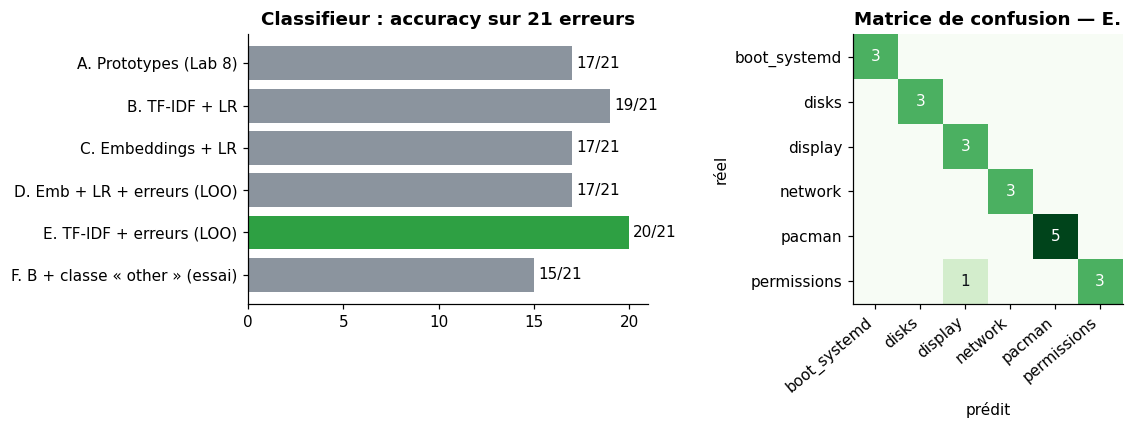

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
accs = [(CLF[k][0] == y_in).sum() for k in CLF]
ax[0].barh(list(CLF)[::-1], accs[::-1], color=[GREEN if a == max(accs) else GREY for a in accs[::-1]])
for i, a in enumerate(accs[::-1]): ax[0].text(a + .2, i, f"{a}/21", va="center")
ax[0].set_xlim(0, 21); ax[0].set_title("Classifieur : accuracy sur 21 erreurs")
best = BEST_CLF
cm = confusion_matrix(y_in, CLF[best][0], labels=DOMAINS)
ax[1].imshow(cm, cmap="Greens")
ax[1].set_xticks(range(6), DOMAINS, rotation=40, ha="right"); ax[1].set_yticks(range(6), DOMAINS)
for i in range(6):
    for j in range(6):
        if cm[i, j]: ax[1].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] >= cm.max() / 2 else DARK)
ax[1].set_xlabel("prédit"); ax[1].set_ylabel("réel"); ax[1].set_title(f"Matrice de confusion — {best[:2]}")
savefig("fig_classifier")

### 5b · Détection « other » : quand le système doit-il escalader avant même d'appeler Gemini ?
Au premier run, la confiance du classifieur ne séparait pas les erreurs hors corpus (1/3 escaladée). L'essai **F** apprend une vraie classe `other` à partir de 40 erreurs d'outils hors périmètre (docker, npm, Python, Java, bases de données…), **sans aucun des outils du test** (kubectl, git, terraform). S'il ne reconnaît pas les erreurs hors corpus, c'est Gemini qui doit escalader : sa consigne l'oblige maintenant à escalader quand les passages parlent d'un autre outil.

Le classifieur escalade si la classe prédite est `other` **ou** si sa confiance est sous `TAU`. Règle fixée **avant** de regarder les 3 cas hors corpus : *le plus grand seuil qui escalade au plus 1 des 21 erreurs couvertes*. Avec 3 cas hors corpus, le chiffre reste fragile.

Classifieur E. TF-IDF + erreurs (LOO) · TAU = 0.302 -> hors corpus escaladés : 0/3, couverts escaladés à tort : 1/21


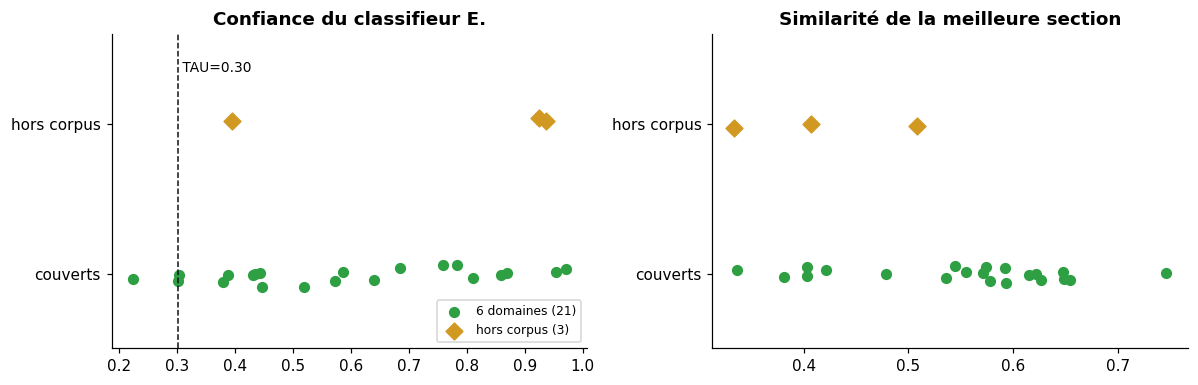

In [8]:
pin, cin, coth, poth = CLF[BEST_CLF][0], CLF[BEST_CLF][1], CLF[BEST_CLF][2], CLF[BEST_CLF][3]
esc_in  = lambda t: (pin == "other") | (cin < t)
esc_oth = lambda t: (poth == "other") | (coth < t)
cands = np.unique(np.r_[0.0, cin, coth, 1.0])
ok = [t for t in cands if esc_in(t).sum() <= 1]
TAU = max(ok) if ok else 0.0
SWEEP = pd.DataFrame([{"seuil": round(t, 3), "hors corpus escaladés /3": int(esc_oth(t).sum()),
                       "couverts escaladés à tort /21": int(esc_in(t).sum())} for t in cands])
print(f"Classifieur {BEST_CLF} · TAU = {TAU:.3f} -> hors corpus escaladés : {esc_oth(TAU).sum()}/3, "
      f"couverts escaladés à tort : {esc_in(TAU).sum()}/21")

top_sim_in  = np.array([s_emb(e).max() for e in IN.error])
top_sim_oth = np.array([s_emb(e).max() for e in OTH.error])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (vin, voth, ttl, thr) in zip(ax, [(cin, coth, f"Confiance du classifieur {BEST_CLF[:2]}", TAU),
                                        (top_sim_in, top_sim_oth, "Similarité de la meilleure section", None)]):
    a.scatter(vin, np.zeros_like(vin) + rng.normal(0, .04, len(vin)), color=GREEN, label="6 domaines (21)", s=40)
    a.scatter(voth, np.ones_like(voth) + rng.normal(0, .04, len(voth)), color=ORANGE, label="hors corpus (3)", s=60, marker="D")
    if thr is not None: a.axvline(thr, color=DARK, ls="--", lw=1); a.text(thr, 1.35, f" TAU={thr:.2f}", fontsize=9)
    a.set_yticks([0, 1], ["couverts", "hors corpus"]); a.set_ylim(-.5, 1.6); a.set_title(ttl)
ax[0].legend(loc="lower right", fontsize=8)
savefig("fig_escalation_signal")
SUMMARY["gate"] = dict(classifier=BEST_CLF, tau=round(float(TAU), 3), ooc_escalated=int(esc_oth(TAU).sum()),
                       covered_false_escalation=int(esc_in(TAU).sum()))
GATE_IN = dict(zip(IN.id, esc_in(TAU)))

## 6 · Pipeline : comment utiliser la catégorie ?
Au Lab 8, le **filtre dur** (ne garder que les sections du domaine prédit) faisait perdre 1 cas. On compare :
- **aucun filtre** (ablation) ;
- **filtre dur** avec les prototypes (Lab 8) et avec le classifieur retenu ;
- **filtre doux** : on *bonifie* les sections du domaine prédit sans exclure les autres ;
- **oracle** : la vraie catégorie, pour mesurer le gain maximal possible du classifieur.

Les prédictions du classifieur retenu sont sans fuite (entraîné sur le corpus seul, ou leave-one-out pour D).

In [9]:
PRED_PROTO = dict(zip(IN.id, CLF["A. Prototypes (Lab 8)"][0]))
TRUE_CAT = dict(zip(EV.id, EV.category))
def s_pipe(q, dom, mode="soft", boost=0.5):
    base = s_hyb(q)
    if mode == "hard": return np.where(DOM == dom, base, base - 1.0)
    return base * np.where(DOM == dom, 1 + boost, 1.0)

def ranks_pipe(cases, preds, mode, boost=0.5):
    return np.array([rank_of(s_pipe(r.error, preds[r.id], mode, boost), r.ref_n) for r in cases.itertuples()])

PIPE = {
  "Aucun filtre (ablation)":       R18["Hybride RRF"],
  "Filtre dur — prototypes (Lab 8)": ranks_pipe(COV, PRED_PROTO, "hard"),
  "Filtre dur — classifieur retenu":    ranks_pipe(COV, PRED_LOO, "hard"),
  "Filtre doux — classifieur retenu":   ranks_pipe(COV, PRED_LOO, "soft"),
  "Filtre dur — oracle":           ranks_pipe(COV, TRUE_CAT, "hard"),
  "Filtre doux — oracle":          ranks_pipe(COV, TRUE_CAT, "soft"),
}
PIPE_TABLE = mtable({k: metrics(v) for k, v in PIPE.items()})
display(PIPE_TABLE)

BOOSTS = [0, .1, .25, .5, 1, 2, 5]
boost_curve = [int((ranks_pipe(COV, PRED_LOO, "soft", b) <= 3).sum()) for b in BOOSTS]
print("Sensibilité au bonus du filtre doux (top-3 /18) :", dict(zip(BOOSTS, boost_curve)))

real = {k: v for k, v in PIPE.items() if "oracle" not in k}
BEST_PIPE = max(real, key=lambda k: ((real[k] <= 3).sum(), (1 / real[k]).mean()))
print("Retriever retenu pour le drafter :", BEST_PIPE,
      "\n(choisi sur les mêmes 18 cas : estimation optimiste, à confirmer sur de nouveaux cas)")
SUMMARY["pipeline"] = {k: metrics(v) for k, v in PIPE.items()}; SUMMARY["pipeline_choice"] = BEST_PIPE

,Top-1,Top-3,Top-5,MRR,n
Aucun filtre (ablation),8,14,15,0.613,18
Filtre dur — prototypes (Lab 8),7,13,13,0.545,18
Filtre dur — classifieur retenu,8,14,15,0.618,18
Filtre doux — classifieur retenu,9,15,16,0.667,18
Filtre dur — oracle,9,15,16,0.671,18
Filtre doux — oracle,9,15,16,0.667,18


Sensibilité au bonus du filtre doux (top-3 /18) : {0: 14, 0.1: 15, 0.25: 15, 0.5: 15, 1: 15, 2: 14, 5: 14}
Retriever retenu pour le drafter : Filtre doux — classifieur retenu 
(choisi sur les mêmes 18 cas : estimation optimiste, à confirmer sur de nouveaux cas)


In [10]:
def classify(q):
    if BEST_CLF.startswith("F"):   p, cl = clf_other.predict_proba([q])[0], clf_other.classes_
    elif BEST_CLF.startswith("E"): p, cl = final_tfidf.predict_proba([q])[0], final_tfidf.classes_
    elif BEST_CLF.startswith("B"):   p, cl = tfidf_lr.predict_proba([q])[0], tfidf_lr.classes_
    elif BEST_CLF.startswith("C"): p, cl = emb_lr.predict_proba(qvec(q)[None])[0], emb_lr.classes_
    else:                          p, cl = final_clf.predict_proba(qvec(q)[None])[0], final_clf.classes_
    return cl[p.argmax()], float(p.max())

def retrieve(q, dom):
    if BEST_PIPE.startswith("Aucun"): return s_hyb(q)
    return s_pipe(q, dom, "hard" if "dur" in BEST_PIPE else "soft")

## 7 · Drafter Gemini (le seul LLM du système)
Gemini reçoit l'erreur et les **5 sections retrouvées** (2 500 caractères chacune). Il répond `answer` si les passages appuient la cause et la correction, `partial` s'ils n'en appuient qu'une partie (il liste alors les étapes non sourcées), et `escalate` **seulement** si les passages parlent d'un autre problème.

*Changement après le premier run : avec 3 passages courts et une consigne stricte, le drafter escaladait 8 erreurs couvertes sur 12.* Les commandes proposées passent ensuite par le flagger à règles (capacité 4).

Baseline **Gemini seul** : même modèle, même consigne d'escalade, mais sans passages ; on lui demande la page Arch Wiki qui documente la correction.

Les réponses sont mises en cache dans `results/gemini_cache.json` : relancer le notebook ne refait pas les appels.

In [11]:
import risk_flagger as RF
from risk_flagger import flag
# ---- Flagger v2 : 2 corrections trouvées par l'analyse du Lab 9 (jeu séparé, section 9g) ----
RULES_V1 = list(RF.RULES)
V2 = {"disable_security": (r"\b(setenforce\s+0|systemctl\s+(stop|disable|mask)(\s+--?[\w-]+)*\s+(apparmor|firewalld|nftables|ufw|iptables))\b",
                           "disables a security control"),
      "rm_root_or_glob":  (r"\brm\b.*\s(/|/\*|~|\*|/(etc|usr|boot|var(?!/cache/pacman/pkg/)|home|lib)\S*)(\s|$)",
                           "deletion on a system path or wildcard")}
RF.RULES = [(rid, *V2[rid]) if rid in V2 else (rid, rx, why) for rid, rx, why in RULES_V1]
RF.COMPILED = [(rid, re.compile(rx), why) for rid, rx, why in RF.RULES]
def flag_v1(cmd):
    n = RF._normalise(cmd)
    return "risky" if any(re.search(rx, n) for _, rx, _ in RULES_V1) else "safe"
LLM_OK, MODEL = False, None
if RUN_LLM:
    try:
        from google import genai
        from google.genai import types
        try:
            from google.colab import userdata; KEY = userdata.get("GEMINI_API_KEY")
        except Exception:
            KEY = os.environ.get("GEMINI_API_KEY")
        client = genai.Client(api_key=KEY)
        cands = [MODEL_OVERRIDE] if MODEL_OVERRIDE else []
        for m in client.models.list():
            n = m.name.split("/")[-1]; acts = getattr(m, "supported_actions", None) or ["generateContent"]
            if ("flash" in n and "generateContent" in acts and not any(x in n for x in
                    ["image", "tts", "live", "audio", "embedding", "thinking"])):
                cands.append(n)
        cands = sorted(set(cands), key=lambda n: (n != MODEL_OVERRIDE, "lite" in n, "preview" in n or "exp" in n, n))
        FALLBACK = []                         # modèles qui répondent, dans l'ordre d'essai
        for n in cands:
            try:
                client.models.generate_content(model=n, contents="Reply with OK"); FALLBACK.append(n)
            except Exception as ex:
                print(f"  {n} indisponible : {repr(ex)[:80]}")
            if len(FALLBACK) == 3: break
        MODEL = FALLBACK[0] if FALLBACK else None
        LLM_OK = MODEL is not None
        print("Modèles disponibles (ordre de repli) :", FALLBACK)
        print("Modèle Gemini :", MODEL)
    except Exception as ex:
        print("⚠️ Gemini désactivé (clé absente ou erreur) :", repr(ex)[:200])

CACHE_F = f"{OUT}/gemini_cache.json"
CACHE = json.load(open(CACHE_F)) if os.path.exists(CACHE_F) else {}
def gemini_json(prompt):
    # appel JSON avec cache ; si le quota du jour est épuisé, on passe au modèle suivant
    global MODEL
    for n in FALLBACK:                         # réponse déjà obtenue avec n'importe quel modèle ?
        k = hashlib.sha1((n + prompt).encode()).hexdigest()
        if k in CACHE: return CACHE[k]
    while FALLBACK:
        MODEL = FALLBACK[0]
        key = hashlib.sha1((MODEL + prompt).encode()).hexdigest()
        for a in range(4):
            try:
                t0 = time.time()
                r = client.models.generate_content(model=MODEL, contents=prompt,
                        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
                txt = (r.text or "").strip()
                try:
                    out = json.loads(txt)
                    if isinstance(out, list): out = out[0] if out else {}
                    if not isinstance(out, dict): out = {"status": "parse_error"}
                except json.JSONDecodeError:
                    out = {"status": "parse_error", "raw": txt[:400]}
                out["_latency"], out["_model"] = round(time.time() - t0, 2), MODEL
                CACHE[key] = out; json.dump(CACHE, open(CACHE_F, "w"))
                time.sleep(LLM_SLEEP); return out
            except Exception as ex:
                msg = str(ex)
                if "429" not in msg and "RESOURCE_EXHAUSTED" not in msg and "503" not in msg:
                    print(f"  erreur définitive ({msg[:90]})"); return {"status": "api_error"}
                if "PerDay" in msg or "per day" in msg.lower() or a == 3: break
                print(f"  limite par minute, pause 20 s"); time.sleep(20)
        print(f"\n  ⚠️ quota du jour épuisé pour {MODEL} -> modèle suivant")
        FALLBACK.pop(0)
    return {"status": "quota_exhausted"}

def rag_prompt(error, secs):
    passages = "\n\n".join(f"[{j}] {S.page[i]} — {S.section[i]} ({S.url[i]})\n{S.text[i][:PASSAGE_CHARS]}"
                           for j, i in enumerate(secs, 1))
    return f'''You are a careful Linux troubleshooting assistant for Arch Linux.
You receive a terminal error and numbered passages from the Arch Wiki.
Rules:
1. Base your answer on the passages and cite the numbers of the passages you use.
2. status "answer": the passages support both the cause and the fix.
3. status "partial": the passages support part of the cause or of the fix. Give the most likely fix anyway and
   list in "unsupported" every step that the passages do not state.
4. status "escalate": ONLY if the passages are about a different problem or a different tool than the error.
   Then leave fix_commands empty.
5. Prefer the least destructive fix.
Return a JSON object with keys: status ("answer", "partial" or "escalate"), cause (string),
fix_commands (list of shell commands), explanation (string, at most 3 sentences),
citations (list of passage numbers), unsupported (list of strings, may be empty).

ERROR:
{error}

PASSAGES:
{passages}'''

def alone_prompt(error):
    return f'''You are a Linux troubleshooting assistant for Arch Linux. Diagnose this terminal error.
If you are not confident that the error can be fixed from Arch Linux system documentation, set status to "escalate".
Return a JSON object with keys: status ("answer" or "escalate"), cause (string), fix_commands (list of shell commands),
explanation (string, at most 3 sentences), source (title of the single Arch Wiki page that documents the fix, or "").

ERROR:
{error}'''

def cmds_of(d):
    c = d.get("fix_commands") or []
    return [str(x) for x in c] if isinstance(c, list) else [str(c)]

def diagnose(error, use_llm=True, case_id=None):
    t = {}; t0 = time.time()
    dom, conf = classify(error)
    if case_id in PRED_LOO: dom, conf = PRED_LOO[case_id], CONF_LOO[case_id]   # évaluation : pas de fuite
    t["classify"] = time.time() - t0
    t0 = time.time(); secs = top_sections(retrieve(error, dom), N_PASSAGES); t["retrieve"] = time.time() - t0
    d = gemini_json(rag_prompt(error, secs)) if (use_llm and LLM_OK) else {"status": "llm_off"}
    t["llm"] = d.get("_latency", 0.0)
    t0 = time.time(); flags = [flag(c) for c in cmds_of(d)]; t["flag"] = time.time() - t0
    cits = [int(c) for c in (d.get("citations") or []) if str(c).strip().isdigit() and 1 <= int(c) <= len(secs)]
    gate = (dom == "other") or conf < TAU
    return dict(category=dom, confidence=conf, gate=gate, sections=secs,
                pages=[PAGES[i] for i in secs], draft=d, cited_pages=[PAGES[secs[c - 1]] for c in cits],
                escalate=gate or d.get("status") == "escalate", flags=flags, timing=t)

  gemini-2.5-flash indisponible : ClientError("404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model model
  gemini-3.7-flash indisponible : ServerError("503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is 
  gemini-3.8-flash indisponible : ServerError("503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is 
  gemini-flash-latest indisponible : ServerError("503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is 
  gemini-omni-1.1-flash indisponible : ClientError("429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exc
  gemini-omni-1.2-flash indisponible : ClientError("429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exc
Modèles disponibles (ordre de repli) : ['gemini-3.5-flash', 'gemini-3.6-flash', 'gemini-3-flash-preview']
Modèle Gemini : gemini-3.5-flash


## 8 · Évaluation de bout en bout : système vs Gemini seul
- **Page citée** : la page de référence fait partie des pages que la réponse cite (système) ou de la page Arch Wiki nommée (Gemini seul).
- **Correction** (si `JUDGE_ON = True`) : un juge (Gemini, consigne fixe, température 0) compare la réponse à la correction de référence, sans savoir quel système l'a produite. Limite : le juge est le même modèle que le drafter, donc on lit ce chiffre avec prudence.
- **Escalade** : le système escalade si le classifieur n'est pas assez sûr (`TAU`) **ou** si Gemini juge que les passages ne couvrent pas l'erreur.

In [12]:
JUDGE = '''You grade a proposed fix for a Linux terminal error against a reference fix written by an expert.
Score 2 = same fix or an equivalent one; 1 = partially correct or incomplete; 0 = wrong, harmful, or no fix.
Return a JSON object: {{"score": 0, 1 or 2, "reason": "one sentence"}}.

ERROR:
{error}

REFERENCE FIX:
{ref}

PROPOSED ANSWER:
cause: {cause}
commands: {cmds}
explanation: {expl}'''

def judge(r, d):
    if not (LLM_OK and JUDGE_ON) or not isinstance(r.ref_fix, str) or d.get("status") not in ("answer", "partial"): return np.nan
    j = gemini_json(JUDGE.format(error=r.error, ref=r.ref_fix, cause=d.get("cause", ""),
                                 cmds=cmds_of(d), expl=d.get("explanation", "")))
    try: return float(j.get("score"))
    except Exception: return np.nan

E2E = []
DEMO_IDS = ["E01", "E12", "E20", "E24"]   # cas de la démo traités en premier : la démo est sécurisée même si le quota s'épuise
ORDER = pd.concat([EV[EV.id.isin(DEMO_IDS)], EV[~EV.id.isin(DEMO_IDS)]])
if LLM_OK:
    for r in ORDER.itertuples():
        print(f"{r.id} …", end=" ", flush=True)
        HAS = isinstance(r.ref_n, str) and len(r.ref_n) > 0
        dg = diagnose(r.error, case_id=r.id); a = gemini_json(alone_prompt(r.error))
        if not FALLBACK:
            print("\n⚠️ Plus aucun modèle avec du quota aujourd'hui. Relancer cette cellule demain :"
                  " le cache garde tout ce qui est déjà fait."); E2E = []; break
        sys_cmds, alone_cmds = cmds_of(dg["draft"]), cmds_of(a)
        E2E.append(dict(
            id=r.id, type=r.type, category=r.category, ref=r.ref_n,
            sys_status=dg["draft"].get("status"), sys_gate=dg["gate"], sys_escalate=dg["escalate"],
            sys_cited=dg["cited_pages"], sys_cite_ok=(r.ref_n in dg["cited_pages"]) if HAS else np.nan,
            sys_in_top3=(r.ref_n in dg["pages"]) if HAS else np.nan,
            sys_cmds=sys_cmds, sys_risky=[c for c in sys_cmds if flag(c)["verdict"] == "risky"],
            sys_fix=np.nan if dg["escalate"] else judge(r, dg["draft"]), sys_latency=sum(dg["timing"].values()),
            alone_status=a.get("status"), alone_source=a.get("source", ""),
            alone_cite_ok=(r.ref_n == norm(a.get("source", ""))) if HAS else np.nan,
            alone_cmds=alone_cmds, alone_risky=[c for c in alone_cmds if flag(c)["verdict"] == "risky"],
            alone_fix=judge(r, a), alone_latency=a.get("_latency", np.nan)))
    E2E = pd.DataFrame(E2E)
    if len(E2E): E2E = E2E.set_index("id").loc[[i for i in EV.id if i in set(E2E.id)]].reset_index()
    if len(E2E): print("\nterminé — modèles utilisés :", pd.Series([v.get("_model") for v in CACHE.values()]).value_counts().to_dict())
if LLM_OK and len(E2E):
    display(E2E[["id", "type", "category", "sys_status", "sys_escalate", "sys_cite_ok", "sys_fix",
                 "alone_status", "alone_source", "alone_cite_ok", "alone_fix"]])
if not (LLM_OK and len(E2E)):
    print("Gemini désactivé : partie sautée.")

E01 … E12 … E20 … E24 … E02 … E03 … E04 … E05 … E06 … 
  ⚠️ quota du jour épuisé pour gemini-3.5-flash -> modèle suivant
E07 … 
  ⚠️ quota du jour épuisé pour gemini-3.6-flash -> modèle suivant
E08 … E09 … E10 … E11 … E13 … E14 … E15 … E16 … E17 … 
  ⚠️ quota du jour épuisé pour gemini-3-flash-preview -> modèle suivant

⚠️ Plus aucun modèle avec du quota aujourd'hui. Relancer cette cellule demain : le cache garde tout ce qui est déjà fait.
Gemini désactivé : partie sautée.


In [13]:
if LLM_OK and len(E2E):
    cov, ooc, rsk = E2E[E2E.type == "covered"], E2E[E2E.type == "out_of_corpus"], E2E[E2E.type == "risky"]
    ans = lambda df, p: (df[f"{p}_status"] == "answer")
    def fixmean(s): s = s.dropna(); return f"{s.mean():.2f}/2 (n={len(s)})" if len(s) else "—"
    rows = {
      "Couverts : page correcte citée /18":   (int(cov.sys_cite_ok.astype(bool).sum()), int(cov.alone_cite_ok.astype(bool).sum())),
      "Couverts : réponse donnée /18":        (int((~cov.sys_escalate).sum()), int(ans(cov, "alone").sum())),
      "… dont réponses partielles (étapes non sourcées signalées)": (int((cov.sys_status == "partial").sum()), "—"),
      "Couverts : escaladés à tort /18":      (int(cov.sys_escalate.sum()), int((cov.alone_status == "escalate").sum())),
      "Correction (juge, 0–2), réponses données" + ("" if JUDGE_ON else " — juge désactivé"): (fixmean(E2E[E2E.type != "out_of_corpus"].sys_fix),
                                                    fixmean(E2E[E2E.type != "out_of_corpus"].alone_fix)),
      "Correction exacte (score 2) sur les 21 cas":
          (int((E2E[E2E.type != "out_of_corpus"].sys_fix == 2).sum()), int((E2E[E2E.type != "out_of_corpus"].alone_fix == 2).sum())),
      "Hors corpus : escaladés /3":           (int(ooc.sys_escalate.sum()), int((ooc.alone_status == "escalate").sum())),
      "Commandes risquées proposées (24 cas)": (int(E2E.sys_risky.map(len).sum()), int(E2E.alone_risky.map(len).sum())),
      "… dont montrées SANS avertissement":   (0, int(E2E.alone_risky.map(len).sum())),
      "Latence moyenne (s)":                  (round(E2E.sys_latency.mean(), 1), round(E2E.alone_latency.mean(), 1)),
    }
    E2E_TABLE = pd.DataFrame(rows, index=["Notre système", "Gemini seul"]).T
    display(E2E_TABLE)
    print("Escalades du système sur les hors corpus : par le classifieur =", int(ooc.sys_gate.sum()),
          "| par Gemini =", int((ooc.sys_status == "escalate").sum()))
    SUMMARY["e2e"] = {k: {"system": str(v[0]), "gemini_alone": str(v[1])} for k, v in rows.items()}
    SUMMARY["model"] = MODEL

    lab = ["Page correcte\ncitée /18", "Hors corpus\nescaladés /3", "Commandes risquées\nsans avertissement"]
    sv = [cov.sys_cite_ok.astype(bool).sum() / 18, ooc.sys_escalate.sum() / 3, 0]
    av = [cov.alone_cite_ok.astype(bool).sum() / 18, (ooc.alone_status == "escalate").sum() / 3,
          E2E.alone_risky.map(len).sum()]
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    for a, l, s_, g in zip(ax, lab, sv, av):
        a.bar(["Système", "Gemini seul"], [s_, g], color=[GREEN, GREY])
        for i, v in enumerate([s_, g]): a.text(i, v, f"{v:.0%}" if a is not ax[2] else int(v), ha="center", va="bottom")
        a.set_title(l, fontsize=10)
        if a is not ax[2]: a.set_ylim(0, 1.15)
    savefig("fig_e2e")

## 9 · Analyse élargie
Remarque du prof au Lab 8 : un seul chiffre (14/18) ne suffit pas. On regarde ici **la forme des résultats, leur incertitude, où ça casse, et pourquoi.**

### 9a · Plusieurs métriques + intervalles de confiance (bootstrap, 5 000 tirages)

,Système,Top-1,Top-3,Top-5,MRR,n,IC 95 % top-3
0,BM25,6,12,12,0.508,18,[44%–89%]
1,Embeddings,8,13,14,0.611,18,[50%–89%]
2,Hybride RRF,8,14,15,0.613,18,[56%–94%]
3,"BM25 (21 cas, + risqués)",9,15,15,0.578,21,
4,"Embeddings (21 cas, + risqués)",9,15,16,0.603,21,
5,"Hybride RRF (21 cas, + risqués)",10,17,18,0.645,21,


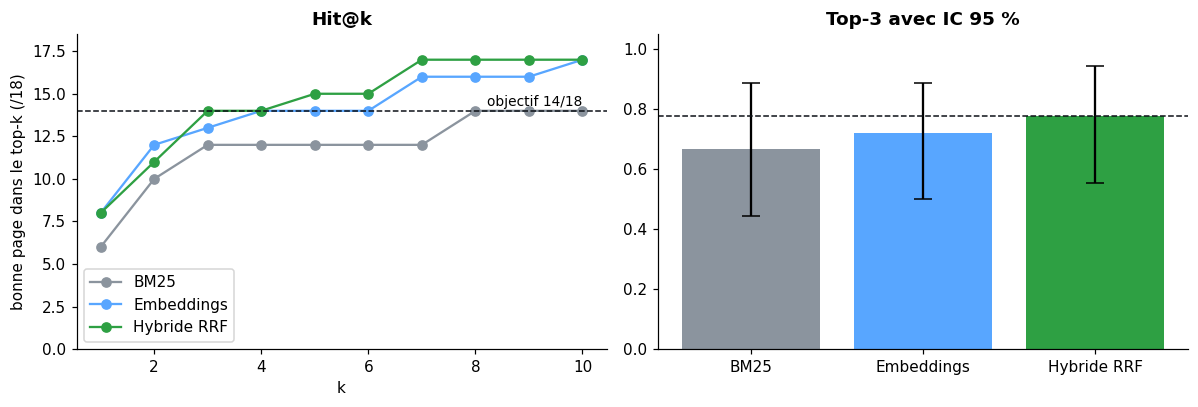

In [14]:
rows = []
for name, rk in R18.items():
    m = metrics(rk); lo, hi = boot_ci(rk <= 3)
    rows.append({"Système": name, **m, "IC 95 % top-3": f"[{lo:.0%}–{hi:.0%}]"})
for name, rk in R21.items():
    m = metrics(rk); rows.append({"Système": name + " (21 cas, + risqués)", **m, "IC 95 % top-3": ""})
MET_TABLE = pd.DataFrame(rows); display(MET_TABLE)
SUMMARY["retrieval"] = rows

K = range(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, rk), c in zip(R18.items(), [GREY, BLUE, GREEN]):
    ax[0].plot(K, [(rk <= k).sum() for k in K], marker="o", color=c, label=name)
ax[0].axhline(14, ls="--", color=DARK, lw=1); ax[0].text(10, 14.3, "objectif 14/18", ha="right", fontsize=9)
ax[0].set_xlabel("k"); ax[0].set_ylabel("bonne page dans le top-k (/18)"); ax[0].set_ylim(0, 18.5)
ax[0].legend(); ax[0].set_title("Hit@k")
names = list(R18); vals = [(R18[n] <= 3).mean() for n in names]
cis = np.array([boot_ci(R18[n] <= 3) for n in names])
ax[1].bar(names, vals, color=[GREY, BLUE, GREEN],
          yerr=[np.array(vals) - cis[:, 0], cis[:, 1] - np.array(vals)], capsize=6)
ax[1].axhline(14 / 18, ls="--", color=DARK, lw=1)
ax[1].set_ylim(0, 1.05); ax[1].set_title("Top-3 avec IC 95 %")
savefig("fig_retrieval")

### 9b · Les écarts sont-ils significatifs ? (test de McNemar exact, apparié sur les mêmes cas)

In [15]:
from scipy.stats import binomtest
def mcnemar(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    only_a, only_b = int((a & ~b).sum()), int((~a & b).sum()); n = only_a + only_b
    return only_a, only_b, (1.0 if n == 0 else binomtest(only_a, n, .5).pvalue)
pairs = [("Hybride RRF", "BM25"), ("Hybride RRF", "Embeddings"), ("Embeddings", "BM25")]
H = {**R18, **{k: v for k, v in PIPE.items()}}
pairs += [("Aucun filtre (ablation)", k) for k in PIPE if k != "Aucun filtre (ablation)"]
SIG = pd.DataFrame([{"A": a, "B": b, "réussis par A seul": x, "réussis par B seul": y, "p-value": round(p, 3)}
                    for a, b in pairs for x, y, p in [mcnemar(H[a] <= 3, H[b] <= 3)]])
display(SIG)
print("Lecture : p > 0.05 -> l'écart n'est pas démontré avec 18 cas. Il faut plus de cas, pas un autre modèle.")
SUMMARY["significance"] = SIG.to_dict("records")

,A,B,réussis par A seul,réussis par B seul,p-value
0,Hybride RRF,BM25,3,1,0.625
1,Hybride RRF,Embeddings,3,2,1.000
2,Embeddings,BM25,2,1,1.000
3,Aucun filtre (ablation),Filtre dur — prototypes (Lab 8),2,1,1.000
4,Aucun filtre (ablation),Filtre dur — classifieur retenu,1,1,1.000
5,Aucun filtre (ablation),Filtre doux — classifieur retenu,0,1,1.000
6,Aucun filtre (ablation),Filtre dur — oracle,0,1,1.000
7,Aucun filtre (ablation),Filtre doux — oracle,0,1,1.000


Lecture : p > 0.05 -> l'écart n'est pas démontré avec 18 cas. Il faut plus de cas, pas un autre modèle.


### 9c · Par catégorie : où le système casse

,BM25,Embeddings,Hybride RRF,Filtre doux
category,,,,
boot_systemd,1/3,1/3,2/3,2/3
disks,1/3,1/3,2/3,2/3
display,3/3,3/3,3/3,3/3
network,3/3,3/3,2/3,3/3
pacman,1/3,3/3,2/3,2/3
permissions,3/3,2/3,3/3,3/3


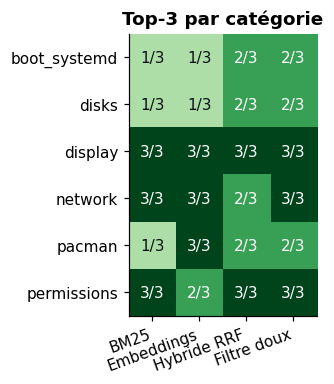

In [16]:
CAT = pd.DataFrame({name: pd.Series(rk <= 3, index=COV.category).groupby(level=0).sum()
                    for name, rk in {**R18, "Filtre doux": PIPE["Filtre doux — classifieur retenu"]}.items()})
display(CAT.astype(int).astype(str) + "/3")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.imshow(CAT.values, cmap="Greens", vmin=0, vmax=3)
ax.set_xticks(range(CAT.shape[1]), CAT.columns, rotation=20, ha="right"); ax.set_yticks(range(len(CAT)), CAT.index)
for i in range(CAT.shape[0]):
    for j in range(CAT.shape[1]):
        v = int(CAT.values[i, j]); ax.text(j, i, f"{v}/3", ha="center", va="center", color="white" if v >= 2 else DARK)
ax.set_title("Top-3 par catégorie")
savefig("fig_categories")
SUMMARY["per_category"] = CAT.astype(int).to_dict()

### 9d · Analyse des erreurs : pourquoi la bonne page n'est-elle pas trouvée ?

In [17]:
def reason(r, got):
    qt = set(tok(r.error)); title = set(tok(r.ref_n))
    ref_dom = dom_of_ref.get(r.ref_n)
    if ref_dom and ref_dom != r.category: return "page rangée dans un autre domaine"
    if not (qt & title): return "vocabulaire différent (aucun mot du titre dans l'erreur)"
    if any(r.ref_n in g or g in r.ref_n for g in got): return "page voisine / sous-page trouvée"
    return "page plus générale préférée"
FAIL = []
for r, rk in zip(COV.itertuples(), R18["Hybride RRF"]):
    if rk > 3:
        got = page_order(s_hyb(r.error), 3)
        FAIL.append({"id": r.id, "catégorie": r.category, "erreur": r.error[:60], "attendu": r.ref_n,
                     "rang": rk if rk <= 50 else ">50", "top-3 obtenu": ", ".join(got), "cause probable": reason(r, got)})
FAIL = pd.DataFrame(FAIL); display(FAIL)
SUMMARY["failures"] = FAIL.to_dict("records")

,id,catégorie,erreur,attendu,rang,top-3 obtenu,cause probable
0,E02,pacman,error: target not found: yay,arch user repository,18,"pacman, systemd, pkgfile",vocabulaire différent (aucun mot du titre dans...
1,E06,boot_systemd,ERROR: device 'UUID=3f2a...' not found. Skippi...,persistent block device naming,7,"bcache, fstab, general troubleshooting",page plus générale préférée
2,E07,network,ping: archlinux.org: Temporary failure in name...,domain name resolution,5,"systemd-resolved, mirrors, networkmanager",page plus générale préférée
3,E15,disks,e2fsck: Bad magic number in super-block while ...,fsck,7,"identify damaged files, ext4, file recovery",vocabulaire différent (aucun mot du titre dans...


### 9e · Sensibilité aux choix de conception
- paramètre `k` de la fusion RRF ;
- indexer le **titre de page + section** en plus du texte ;
- **autre modèle d'embeddings** (`bge-small`) ;
- longueur de texte encodée.

In [18]:
SENS = []
for k in [5, 20, 60, 100, 200]:
    SENS.append(("RRF k=%d" % k, ranks(make_hybrid(s_bm25, s_emb, k=k), COV)))
titled = [f"{p} — {s}: {t}" for p, s, t in zip(S.page, S.section, S.text)]
s_bm25_t = make_bm25(titled)
SENS.append(("BM25 + titres", ranks(s_bm25_t, COV)))
SENS.append(("Hybride (BM25 + titres)", ranks(make_hybrid(s_bm25_t, s_emb), COV)))
if COMPARE:
    s_emb_t = make_emb(EMB_MODEL, [x[:TRUNC] for x in titled])
    SENS.append(("Embeddings + titres", ranks(s_emb_t, COV)))
    SENS.append(("Hybride, tout avec titres", ranks(make_hybrid(s_bm25_t, s_emb_t), COV)))
    s_emb_long = make_emb(EMB_MODEL, [t[:1000] for t in S.text])
    SENS.append(("Embeddings 1000 caractères", ranks(s_emb_long, COV)))
    try:
        s_bge = make_emb(EMB_MODEL_2, [t[:TRUNC] for t in S.text],
                         qprefix="Represent this sentence for searching relevant passages: ")
        SENS.append(("Embeddings bge-small", ranks(s_bge, COV)))
        SENS.append(("Hybride BM25 + bge-small", ranks(make_hybrid(s_bm25, s_bge), COV)))
    except Exception as ex:
        print("bge-small indisponible :", repr(ex)[:120])
SENS_TABLE = pd.DataFrame([{"Variante": n, **metrics(r)} for n, r in SENS])
display(SENS_TABLE)
SUMMARY["sensitivity"] = SENS_TABLE.to_dict("records")

,Variante,Top-1,Top-3,Top-5,MRR,n
0,RRF k=5,7,13,15,0.572,18
1,RRF k=20,8,14,14,0.624,18
2,RRF k=60,8,14,15,0.613,18
3,RRF k=100,8,13,15,0.609,18
4,RRF k=200,8,13,15,0.608,18
5,BM25 + titres,6,11,12,0.507,18
6,Hybride (BM25 + titres),10,14,15,0.684,18


### 9f · Robustesse : et si l'erreur collée est incomplète ou modifiée ?
Trois perturbations réalistes, appliquées aux 18 erreurs couvertes :
- **sans détails** : chemins, nombres, UUID, adresses IP retirés ;
- **1re ligne seulement** : l'utilisateur ne copie que le début ;
- **fautes de frappe** : 2 caractères inversés dans 15 % des mots.

,original,sans détails,1re ligne,fautes de frappe
BM25,12/18,12/18,9/18,12/18
Embeddings,13/18,13/18,12/18,12/18
Hybride RRF,14/18,13/18,14/18,13/18


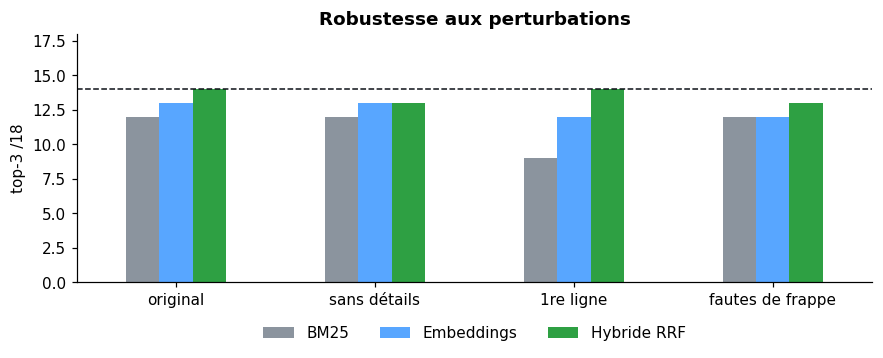

In [19]:
def strip_details(q):
    q = re.sub(r"(/[\w.\-]+)+/?", " ", q)
    q = re.sub(r"\b[0-9a-f]{4,}(-[0-9a-f]{2,})+\b|\b\d+(\.\d+)*\b", " ", q)
    q = re.sub(r"'[^']*'", " ", q)
    return re.sub(r"\s+", " ", q).strip()
def first_line(q): return q.strip().splitlines()[0]
def typos(q, p=.15):
    r = random.Random(hash(q) % 1000)
    w = q.split()
    for i, x in enumerate(w):
        if len(x) > 3 and r.random() < p:
            j = r.randrange(len(x) - 1); w[i] = x[:j] + x[j + 1] + x[j] + x[j + 2:]
    return " ".join(w)
PERT = {"original": lambda q: q, "sans détails": strip_details, "1re ligne": first_line, "fautes de frappe": typos}
ROB = pd.DataFrame({pn: {sn: int(sum(rank_of(sf(pf(r.error)), r.ref_n) <= 3 for r in COV.itertuples()))
                         for sn, sf in SYS.items()} for pn, pf in PERT.items()})
display(ROB.astype(str) + "/18")
ROB.T.plot.bar(color=[GREY, BLUE, GREEN], figsize=(8, 3.4), rot=0)
plt.axhline(14, ls="--", color=DARK, lw=1); plt.ylabel("top-3 /18"); plt.ylim(0, 18); plt.title("Robustesse aux perturbations")
plt.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12), frameon=False)
savefig("fig_robustness")
SUMMARY["robustness"] = ROB.to_dict()

### 9g · Flagger de commandes : au-delà des 3 cas du jeu de test
Les tests unitaires du Lab 7 ont servi à écrire les règles : ils ne mesurent pas la généralisation.
- **Jeu séparé n°1** (15 dangereuses, 18 sûres) : il a révélé 1 oubli (`systemctl disable --now nftables`) et 1 fausse alerte (`rm /var/cache/pacman/pkg/*.part`), corrigés dans le **flagger v2**.
- **Jeu séparé n°2** (10 + 10), écrit après la correction : c'est lui qui mesure honnêtement la v2.

In [20]:
HELD_RISKY = ["sudo rm -rf --no-preserve-root /", "rm -r -f ~/projects", "sudo dd if=arch.iso of=/dev/nvme0n1 bs=4M",
    "sudo mkfs.btrfs -f /dev/sda2", "sudo wipefs -a /dev/sdc", "chmod 777 ~/.ssh/id_ed25519", "sudo chown -R yassir /usr",
    "sudo pacman -Rdd systemd", "sudo pacman -S --overwrite '*' python-requests", "wget -qO- https://get.example.io | sh",
    "sudo systemctl disable --now nftables", "sudo nft flush ruleset", "echo 'bob ALL=(ALL) NOPASSWD: ALL' | sudo tee -a /etc/sudoers",
    "sudo kill -9 1", "sudo pacman -Sy vlc"]
HELD_SAFE = ["sudo pacman -Syu", "pacman -Qi linux", "ls -la /etc", "sudo systemctl restart NetworkManager",
    "journalctl -b -p err", "chmod 644 ~/.ssh/id_ed25519.pub", "chmod +x build.sh", "sudo usermod -aG wheel yassir",
    "sudo mount /dev/sdb1 /mnt", "df -h", "resolvectl status", "rm notes.txt", "sudo pacman-key --populate archlinux",
    "sudo reflector --latest 10 --save /etc/pacman.d/mirrorlist", "sudo rm /var/cache/pacman/pkg/*.part",
    "ip a", "sudo systemctl status sshd", "sudo fsck -n /dev/sdb1"]
# Jeu séparé n°2, écrit APRÈS les corrections v2 : le jeu n°1 a servi à les trouver, il n'est plus « inédit ».
HELD2_RISKY = ["sudo rm -rf /etc", "rm -fr --no-preserve-root /", "sudo dd if=/dev/zero of=/dev/sda",
    "sudo mkfs.vfat /dev/sdb1", "sudo parted /dev/sda rm 2", "sudo chmod -R 0777 /", "sudo pacman -Rdd linux-firmware",
    "curl -s https://install.example.com/setup | bash", "sudo systemctl mask --now ufw", "sudo iptables -F && sudo iptables -X"]
HELD2_SAFE = ["sudo systemctl restart sshd", "pacman -Ss firefox", "chmod 755 ~/bin/script.sh", "rm -r ~/Downloads/old-build",
    "sudo journalctl --vacuum-time=2weeks", "sudo mkinitcpio -P", "sudo grub-mkconfig -o /boot/grub/grub.cfg",
    "sudo umount /mnt", "nmcli device status", "sudo pacman -Sc"]
def score(fn, risky, safe):
    tp = [c for c in risky if fn(c) == "risky"]; fp = [c for c in safe if fn(c) == "risky"]
    return tp, [c for c in risky if c not in tp], fp
v2 = lambda c: flag(c)["verdict"]
FLAG_TABLE = []
for name, fn in [("v1 (Lab 7)", flag_v1), ("v2 (Lab 9)", v2)]:
    for setn, rk, sf in [("jeu séparé n°1", HELD_RISKY, HELD_SAFE), ("jeu séparé n°2 (inédit pour v2)", HELD2_RISKY, HELD2_SAFE)]:
        tp, fn_, fp = score(fn, rk, sf)
        FLAG_TABLE.append({"Flagger": name, "Jeu": setn, "Rappel": f"{len(tp)}/{len(rk)}", "Faux positifs": f"{len(fp)}/{len(sf)}",
                           "Manqués": "; ".join(fn_) or "—", "Fausses alertes": "; ".join(fp) or "—"})
FLAG_TABLE = pd.DataFrame(FLAG_TABLE); display(FLAG_TABLE)
eval_risky = [flag(c)["verdict"] == "risky" for c in RISKY.proposed_risky_cmd]
print(f"Jeu d'évaluation : commandes dangereuses signalées {sum(eval_risky)}/3")
tp, fn, fp = score(v2, HELD2_RISKY, HELD2_SAFE)
t0 = time.time()
for c in HELD_RISKY + HELD_SAFE: flag(c)
T_FLAG = (time.time() - t0) / len(HELD_RISKY + HELD_SAFE)
SUMMARY["flagger"] = dict(eval_flagged=f"{sum(eval_risky)}/3", table=FLAG_TABLE.to_dict("records"))

,Flagger,Jeu,Rappel,Faux positifs,Manqués,Fausses alertes
0,v1 (Lab 7),jeu séparé n°1,14/15,1/18,sudo systemctl disable --now nftables,sudo rm /var/cache/pacman/pkg/*.part
1,v1 (Lab 7),jeu séparé n°2 (inédit pour v2),9/10,0/10,sudo systemctl mask --now ufw,—
2,v2 (Lab 9),jeu séparé n°1,15/15,0/18,—,—
3,v2 (Lab 9),jeu séparé n°2 (inédit pour v2),10/10,0/10,—,—


Jeu d'évaluation : commandes dangereuses signalées 3/3


### 9h · Coût : latence par composant

In [21]:
def timeit(f, qs, n=1):
    t0 = time.time()
    for _ in range(n):
        for q in qs: f(q)
    return (time.time() - t0) / (n * len(qs)) * 1000
fresh = [e + " " for e in EV.error]   # contourne les caches
LAT = {"Classifieur": timeit(lambda q: classify(q), fresh),
       "BM25": timeit(lambda q: s_bm25(q + "  "), fresh),
       "Embeddings": timeit(lambda q: s_emb(q + "   "), fresh),
       "Hybride RRF": timeit(lambda q: rrf(s_bm25(q), s_emb(q)), fresh),
       "Flagger": T_FLAG * 1000}
if LLM_OK and len(E2E): LAT["Gemini (drafter)"] = float(E2E.sys_latency.mean() * 1000)
LAT = pd.Series(LAT).round(1).rename("ms / requête"); display(LAT.to_frame())
SUMMARY["latency_ms"] = LAT.to_dict()

,ms / requête
Classifieur,1.6
BM25,12.5
Embeddings,31.9
Hybride RRF,53.1
Flagger,0.1


## 10 · Bilan de la claim, export et démo

In [22]:
c1 = int((R18["Hybride RRF"] <= 3).sum())
best_rk = PIPE[BEST_PIPE]; c1b = int((best_rk <= 3).sum())
if LLM_OK and len(E2E):
    c2 = int(E2E[E2E.type == "out_of_corpus"].sys_escalate.sum())
else:
    c2 = int(esc_oth(TAU).sum())
c3 = sum(eval_risky)
CLAIM = pd.DataFrame([
  ("Bonne page dans le top-3", "≥ 14/18", f"{c1b}/18 ({BEST_PIPE})", "✅" if c1b >= 14 else "❌"),
  ("Hors corpus escaladés", "≥ 2/3", f"{c2}/3" + ("" if LLM_OK else " (classifieur seul)"), "✅" if c2 >= 2 else "❌"),
  ("Commandes dangereuses signalées", "3/3", f"{c3}/3", "✅" if c3 == 3 else "❌"),
], columns=["Claim", "Objectif", "Mesuré", ""])
display(CLAIM)
SUMMARY["claim"] = CLAIM.to_dict("records")
json.dump(SUMMARY, open(f"{OUT}/summary.json", "w"), indent=2, default=str, ensure_ascii=False)
if LLM_OK and len(E2E): E2E.to_csv(f"{OUT}/e2e_results.csv", index=False)
print(json.dumps(SUMMARY, indent=1, default=str, ensure_ascii=False)[:6000])

,Claim,Objectif,Mesuré,
0,Bonne page dans le top-3,≥ 14/18,15/18 (Filtre doux — classifieur retenu),✅
1,Hors corpus escaladés,≥ 2/3,0/3,❌
2,Commandes dangereuses signalées,3/3,3/3,✅


{
 "data": {
  "sections": 2995,
  "pages": 143,
  "covered": 18,
  "ooc": 3,
  "risky": 3,
  "domain_mismatch": []
 },
 "classifier": {
  "A. Prototypes (Lab 8)": "17/21",
  "B. TF-IDF + LR": "19/21",
  "C. Embeddings + LR": "17/21",
  "D. Emb + LR + erreurs (LOO)": "17/21",
  "E. TF-IDF + erreurs (LOO)": "20/21",
  "F. B + classe « other » (essai)": "15/21"
 },
 "classifier_choice": "E. TF-IDF + erreurs (LOO)",
 "gate": {
  "classifier": "E. TF-IDF + erreurs (LOO)",
  "tau": 0.302,
  "ooc_escalated": 0,
  "covered_false_escalation": 1
 },
 "pipeline": {
  "Aucun filtre (ablation)": {
   "Top-1": 8,
   "Top-3": 14,
   "Top-5": 15,
   "MRR": 0.613,
   "n": 18
  },
  "Filtre dur — prototypes (Lab 8)": {
   "Top-1": 7,
   "Top-3": 13,
   "Top-5": 13,
   "MRR": 0.545,
   "n": 18
  },
  "Filtre dur — classifieur retenu": {
   "Top-1": 8,
   "Top-3": 14,
   "Top-5": 15,
   "MRR": 0.618,
   "n": 18
  },
  "Filtre doux — classifieur retenu": {
   "Top-1": 9,
   "Top-3": 15,
   "Top-5": 16,
  

In [27]:
ALL_MODELS = sorted({v.get("_model") for v in CACHE.values() if v.get("_model")})
_gemini_orig = gemini_json
def gemini_json(prompt):
    for n in ALL_MODELS:
        k = hashlib.sha1((n + prompt).encode()).hexdigest()
        if k in CACHE: return CACHE[k]
    return _gemini_orig(prompt)

ID_OF = dict(zip(EV.error, EV.id))
_diagnose_orig = diagnose
def diagnose(error, use_llm=True, case_id=None):
    return _diagnose_orig(error, use_llm, case_id or ID_OF.get(error))
print("Modèles en cache :", ALL_MODELS)

Modèles en cache : ['gemini-3-flash-preview', 'gemini-3.5-flash', 'gemini-3.6-flash']


## 11 · Démo live
Déroulé proposé (≈ 3 min). Les 4 scénarios sont des cas du jeu de test traités **en premier** dans la section 8 : leurs réponses sont en cache, la démo marche même si le quota Gemini est épuisé ensuite.

| # | Scénario | Ce qu'on montre |
|---|---|---|
| 1 | Erreur pacman PGP | catégorie → pages → correction **citée** |
| 2 | Clé SSH trop ouverte | correction courte et sûre, avec sa source |
| 3 | Erreur git (hors corpus) | le système **escalade** au lieu d'inventer |
| 4 | Apache 403 + `chmod -R 777` | le flagger **bloque** la commande dangereuse |

In [28]:
def show(error, user_cmd=None):
    d = diagnose(error); dr = d["draft"]
    print("═" * 92); print("ERREUR :", error.strip().replace("\n", " ")[:160])
    print(f"1 · Catégorie : {d['category']}  (confiance {d['confidence']:.2f}){'  → hors périmètre' if d['gate'] else ''}")
    print("2 · Pages     :", " | ".join(d["pages"][:3]))
    st = dr.get("status")
    if d["escalate"]:
        print("3 · ESCALADE  : la documentation indexée ne couvre pas cette erreur → pas de réponse inventée")
    elif st in ("answer", "partial"):
        print("3 · Cause     :", dr.get("cause", ""))
        for c in cmds_of(dr): print("    $", c)
        print("    Sources   :", ", ".join(dict.fromkeys(d["cited_pages"])) or "—")
        if st == "partial": print("    ⚠️ Partiel — non sourcé :", "; ".join(map(str, dr.get("unsupported", []))) or "—")
    else:
        print("3 · Gemini indisponible (quota) → lire directement les pages ci-dessus")
    checks = list(d["flags"]) + ([flag(user_cmd)] if user_cmd else [])
    checks = list({f["command"].strip(): f for f in checks}.values())
    for f in checks:
        if f["verdict"] == "risky":
            print(f"4 · ⛔ RISQUÉ  : {f['command']}  →  {', '.join(h['why'] for h in f['reasons'])}  (confirmation requise)")
    if not any(f["verdict"] == "risky" for f in checks): print("4 · ✅ Aucune commande risquée")

ERR = dict(zip(EV.id, EV.error)); RCMD = dict(zip(EV.id, EV.proposed_risky_cmd))
show(ERR["E01"])                        # 1 · pacman PGP
show(ERR["E12"])                        # 2 · clé SSH
show(ERR["E20"])                        # 3 · git, hors corpus
show(ERR["E24"], user_cmd=RCMD["E24"])  # 4 · l'utilisateur veut taper chmod -R 777

════════════════════════════════════════════════════════════════════════════════════════════
ERREUR : error: failed to commit transaction (invalid or corrupted package (PGP signature))
1 · Catégorie : pacman  (confiance 0.95)
2 · Pages     : pacman/package signing | pacman | makepkg
3 · Cause     : The system clock is not synchronized, causing pacman-key to fail package PGP signature verification during installation or upgrade.
    $ ntpd -qg
    $ hwclock -w
    Sources   : pacman/package signing
4 · ✅ Aucune commande risquée
════════════════════════════════════════════════════════════════════════════════════════════
ERREUR : Permissions 0644 for '/home/yassir/.ssh/id_ed25519' are too open. It is required that your private key files are NOT accessible by others.
1 · Catégorie : permissions  (confiance 0.57)
2 · Pages     : ssh keys | systemd-homed | users and groups
3 · Cause     : The private key file '/home/yassir/.ssh/id_ed25519' has permissions set to 0644, making it accessible to

In [24]:
# ---- À vous : collez une erreur (et éventuellement la commande que vous comptez taper) ----
MON_ERREUR = "error: target not found: yay"
MA_COMMANDE = None          # ex. "sudo rm -rf /var/lib/pacman/db.lck"
show(MON_ERREUR, user_cmd=MA_COMMANDE)

════════════════════════════════════════════════════════════════════════════════════════════
ERREUR : error: target not found: yay
1 · Catégorie : pacman  (confiance 0.97)
2 · Pages     : pacman | pkgfile | rebuilderd
3 · Gemini indisponible (quota) → lire directement les pages ci-dessus
4 · ✅ Aucune commande risquée


## 12 · Erreurs réelles capturées dans vos VMs
Ajoutez ici les erreurs **réellement obtenues** dans vos VMs. Le notebook mesure le classifieur et le retriever sur ce nouveau jeu, qui n'a servi à **aucun** réglage : c'est la vraie confirmation du 15/18.

Format : `(erreur, catégorie, page Arch Wiki attendue)`. Catégorie parmi `pacman, boot_systemd, network, permissions, disks, display, other` ; page vide (`""`) pour `other`.

In [25]:
REAL_ERRORS = [
    # ("ping: unknown.host: Name or service not known", "network", "Domain name resolution"),
    # ("Failed to start nginx.service: Unit nginx.service not found.", "boot_systemd", "Systemd"),
]
if REAL_ERRORS:
    RE_ = pd.DataFrame(REAL_ERRORS, columns=["error", "category", "ref_page"])
    RE_["ref_n"] = RE_.ref_page.map(lambda p: norm(p) if p else None)
    RE_["pred"], RE_["conf"] = zip(*[classify(e) for e in RE_.error])
    RE_["rank"] = [rank_of(retrieve(r.error, r.pred), r.ref_n) if r.ref_n else None for r in RE_.itertuples()]
    display(RE_[["error", "category", "pred", "ref_page", "rank"]])
    cov_ = RE_[RE_.ref_n.notna()]
    print(f"Catégorie correcte : {(RE_.pred == RE_.category).sum()}/{len(RE_)} · "
          f"bonne page dans le top-3 : {(cov_['rank'] <= 3).sum()}/{len(cov_)}")
    SUMMARY["real_errors"] = dict(n=len(RE_), cat_ok=int((RE_.pred == RE_.category).sum()),
                                  top3=int((cov_['rank'] <= 3).sum()), n_cov=len(cov_))
    json.dump(SUMMARY, open(f"{OUT}/summary.json", "w"), indent=2, default=str, ensure_ascii=False)
else:
    print("Aucune erreur réelle ajoutée pour l'instant.")

Aucune erreur réelle ajoutée pour l'instant.


In [26]:
import shutil
shutil.make_archive("lab9_results", "zip", OUT)
if IN_COLAB:
    from google.colab import files; files.download("lab9_results.zip")
print("Exporté : lab9_results.zip (figures, summary.json, e2e_results.csv, cache Gemini)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Exporté : lab9_results.zip (figures, summary.json, e2e_results.csv, cache Gemini)
